## Cell 0 — Environment & CUDA Check

In [9]:
import subprocess, sys, os

print(f'Python: {sys.version}')
print(f'Python exe: {sys.executable}')

try:
    import torch
    cuda_ok = torch.cuda.is_available()
    print(f'torch version : {torch.__version__}')
    print(f'CUDA available: {cuda_ok}')
    if cuda_ok:
        print(f'GPU name      : {torch.cuda.get_device_name(0)}')
        vram = torch.cuda.get_device_properties(0).total_memory / 1e9
        print(f'VRAM          : {vram:.2f} GB')
    else:
        print('\n[WARNING] CUDA not available in this torch build.')
        print('To fix, run in a terminal (in your venv):')
        print('  pip install torch torchvision --index-url https://download.pytorch.org/whl/cu124')
        print('Then restart this kernel.')
except ImportError:
    print('[ERROR] torch not installed. Run:')
    print('  pip install torch torchvision --index-url https://download.pytorch.org/whl/cu124')

Python: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Python exe: c:\CodeWorld\DL\venv\Scripts\python.exe
torch version : 2.14.1+cu132
CUDA available: True
GPU name      : NVIDIA GeForce RTX 5050 Laptop GPU
VRAM          : 8.55 GB


## Cell 1 — Imports & Paths

In [10]:
import os
import torch
import yaml
import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
from datetime import datetime
from ultralytics import YOLO

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Paths
REPO_ROOT   = Path(r'C:\Projects\mscSem3')
DATASET_DIR = REPO_ROOT / 'Dataset' / 'claude_ds_28sep' / 'dataset_white_hot'
DATA_YAML   = DATASET_DIR / 'data.yaml'
WEIGHTS_PT  = REPO_ROOT / 'Dataset' / 'yolov8n.pt'
RUNS_DIR    = REPO_ROOT / 'runs'

# Fall-back to weights/ dir
if not WEIGHTS_PT.exists():
    alt = REPO_ROOT / 'weights' / 'yolov8n.pt'
    WEIGHTS_PT = alt if alt.exists() else WEIGHTS_PT

print(f'Dataset YAML : {DATA_YAML}  [exists={DATA_YAML.exists()}]')
print(f'Weights      : {WEIGHTS_PT} [exists={WEIGHTS_PT.exists()}]')
print(f'Runs dir     : {RUNS_DIR}')

Dataset YAML : C:\Projects\mscSem3\Dataset\claude_ds_28sep\dataset_white_hot\data.yaml  [exists=True]
Weights      : C:\Projects\mscSem3\Dataset\yolov8n.pt [exists=True]
Runs dir     : C:\Projects\mscSem3\runs


## Cell 2 — Dataset YAML Inspection

In [11]:
with open(DATA_YAML) as f:
    cfg = yaml.safe_load(f)

print('=== data.yaml ===')
for k, v in cfg.items():
    print(f'  {k}: {v}')

NUM_CLASSES = len(cfg['names'])
CLASS_NAMES = list(cfg['names'].values()) if isinstance(cfg['names'], dict) else cfg['names']
print(f'\nClasses ({NUM_CLASSES}): {CLASS_NAMES}')

for split in ['train', 'val', 'test']:
    img_dir = DATASET_DIR / 'images' / split
    n = len(list(img_dir.glob('*'))) if img_dir.exists() else 0
    print(f'  {split:5s}: {n} images')

=== data.yaml ===
  path: C:/Projects/mscSem3/Dataset/claude_ds_28sep/dataset_white_hot
  train: images/train
  val: images/val
  test: images/test
  names: {0: 'nilgai', 1: 'boar', 2: 'cow'}

Classes (3): ['nilgai', 'boar', 'cow']
  train: 4000 images
  val  : 500 images
  test : 500 images


## Cell 3 — GPU & Mixed-Precision Setup

In [12]:
DEVICE  = 'cuda:0' if torch.cuda.is_available() else 'cpu'
USE_AMP = torch.cuda.is_available()

if torch.cuda.is_available():
    props   = torch.cuda.get_device_properties(0)
    VRAM_GB = props.total_memory / 1e9
    print(f'GPU  : {props.name}')
    print(f'VRAM : {VRAM_GB:.1f} GB')
    print(f'SMs  : {props.multi_processor_count}')
    print(f'AMP  : {USE_AMP} (fp16 training)')

    # Maximize GPU throughput
    torch.backends.cudnn.benchmark         = True
    torch.backends.cudnn.deterministic     = False
    torch.backends.cuda.matmul.allow_tf32  = True
    torch.backends.cudnn.allow_tf32        = True
    print('[OK] CuDNN benchmark + TF32 enabled')
else:
    VRAM_GB = 0
    print(f'[WARNING] Running on CPU — training will be slow!')

print(f'\nDevice: {DEVICE}')

GPU  : NVIDIA GeForce RTX 5050 Laptop GPU
VRAM : 8.5 GB
SMs  : 20
AMP  : True (fp16 training)
[OK] CuDNN benchmark + TF32 enabled

Device: cuda:0


## Cell 4 — Batch Size & Worker Setup
> **Windows fix:** `num_workers=0` prevents the `DataLoader worker exited unexpectedly` crash that occurs because Windows cannot fork worker processes inside a Jupyter notebook.

In [13]:
import multiprocessing
CPU_CORES = multiprocessing.cpu_count()

# Tuned for RTX 5050 (~8 GB VRAM)
BATCH_SIZE = 32
IMG_SIZE = 640

# -----------------------------------------------------------------------
# Windows DataLoader fix
# PyTorch uses fork-based multiprocessing for DataLoader workers.
# On Windows inside a Jupyter notebook, forked worker processes crash
# immediately (queue.Empty -> RuntimeError: worker exited unexpectedly).
# Fix: set workers=0 (all data loading on the main thread).
# On Linux/WSL2 you can safely increase this to 4+.
# -----------------------------------------------------------------------
IS_WINDOWS  = os.name == 'nt'
NUM_WORKERS = 0 if IS_WINDOWS else min(4, CPU_CORES)

print(f'Platform   : {"Windows" if IS_WINDOWS else "Linux/Mac"}')
print(f'CPU cores  : {CPU_CORES}')
print(f'VRAM       : {VRAM_GB:.1f} GB')
print(f'Batch size : {BATCH_SIZE}')
print(f'Image size : {IMG_SIZE}')
print(f'Workers    : {NUM_WORKERS}  (0 = single-thread, safe on Windows)')

Platform   : Windows
CPU cores  : 16
VRAM       : 8.5 GB
Batch size : 32
Image size : 640
Workers    : 0  (0 = single-thread, safe on Windows)


## Cell 5 — Training Hyperparameters

In [14]:
RUN_NAME = f"yolov8n_whitehot_{datetime.now().strftime('%d%b_%H%M')}"

TRAIN_CFG = dict(
    # Core
    data         = str(DATA_YAML),
    epochs       = 100,
    imgsz        = IMG_SIZE,
    batch        = BATCH_SIZE,
    device       = DEVICE,

    # Performance
    amp          = USE_AMP,
    workers      = NUM_WORKERS,    # 0 on Windows — avoids DataLoader worker crash
    cache        = False,          # disable cache; use 'disk' if you want faster re-runs

    # Optimiser
    optimizer    = 'AdamW',
    lr0          = 0.001,
    lrf          = 0.01,
    momentum     = 0.937,
    weight_decay = 0.0005,
    warmup_epochs    = 3.0,
    warmup_momentum  = 0.8,
    warmup_bias_lr   = 0.1,

    # Augmentation — tuned for thermal IR (single-channel, no colour)
    hsv_h        = 0.0,   # no hue shift
    hsv_s        = 0.0,   # no saturation shift
    hsv_v        = 0.4,   # brightness variation matters in IR
    degrees      = 10.0,
    translate    = 0.1,
    scale        = 0.5,
    shear        = 2.0,
    perspective  = 0.0,
    flipud       = 0.0,
    fliplr       = 0.5,
    mosaic       = 1.0,
    mixup        = 0.1,
    copy_paste   = 0.0,

    # Loss weights
    box          = 7.5,
    cls          = 0.5,
    dfl          = 1.5,

    # Saving & Logging
    project      = str(RUNS_DIR / 'detect'),
    name         = RUN_NAME,
    save         = True,
    save_period  = 10,
    exist_ok     = True,
    plots        = True,
    verbose      = True,

    # Early stopping
    patience     = 20,

    # Disable mosaic in final epochs for stable fitting
    close_mosaic = 10,
)

print(f'Run name  : {RUN_NAME}')
print(f'Epochs    : {TRAIN_CFG["epochs"]}')
print(f'Batch     : {TRAIN_CFG["batch"]}')
print(f'Workers   : {TRAIN_CFG["workers"]}')
print(f'AMP/fp16  : {TRAIN_CFG["amp"]}')
print(f'Cache     : {TRAIN_CFG["cache"]}')

Run name  : yolov8n_whitehot_29Oct_1221
Epochs    : 100
Batch     : 32
Workers   : 0
AMP/fp16  : True
Cache     : False


## Cell 6 — Load Model & Start Training

In [15]:
model = YOLO(str(WEIGHTS_PT))
print(f'Model loaded : {WEIGHTS_PT}')
print(f'Parameters   : {sum(p.numel() for p in model.model.parameters()):,}')

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    free, total = torch.cuda.mem_get_info()
    print(f'VRAM free before train: {free/1e9:.2f} / {total/1e9:.2f} GB')

Model loaded : C:\Projects\mscSem3\Dataset\yolov8n.pt
Parameters   : 3,157,200
VRAM free before train: 7.12 / 8.55 GB


In [ ]:
model = YOLO(str(RUNS_DIR / 'detect' / 'yolov8n_whitehot_29Oct_0149' / 'weights' / 'last.pt'))

print(f'Model loaded from last.pt')
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Update epochs (you just completed 16 full epochs, so 84 remaining)
TRAIN_CFG['epochs'] = 80

# TRAIN (Start a new run to force the batch size change)
results = model.train(**TRAIN_CFG)

SAVE_DIR = Path(results.save_dir)
BEST_PT  = SAVE_DIR / 'weights' / 'best.pt'
LAST_PT  = SAVE_DIR / 'weights' / 'last.pt'

print(f'\nTraining done!')
print(f'Run dir     : {SAVE_DIR}')
print(f'Best weights: {BEST_PT}')


Model loaded from last.pt
New https://pypi.org/project/ultralytics/8.4.192 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.182  Python-3.12.10 torch-2.14.1+cu132 CUDA:0 (NVIDIA GeForce RTX 5050 Laptop GPU, 8151MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Projects\mscSem3\Dataset\claude_ds_28sep\dataset_white_hot\data.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.

## Cell 7 — Validation

In [17]:
best_model = YOLO(str(BEST_PT))

val_results = best_model.val(
    data    = str(DATA_YAML),
    split   = 'val',
    imgsz   = IMG_SIZE,
    batch   = BATCH_SIZE,
    device  = DEVICE,
    workers = NUM_WORKERS,
    verbose = True,
)

print('\n=== Validation Metrics ===')
print(f'mAP50      : {val_results.box.map50:.4f}')
print(f'mAP50-95   : {val_results.box.map:.4f}')
print(f'Precision  : {val_results.box.mp:.4f}')
print(f'Recall     : {val_results.box.mr:.4f}')

Ultralytics 8.4.182  Python-3.12.10 torch-2.14.1+cu132 CUDA:0 (NVIDIA GeForce RTX 5050 Laptop GPU, 8151MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 1351.1±277.5 MB/s, size: 184.4 KB)
val: Scanning C:\Projects\mscSem3\Dataset\claude_ds_28sep\dataset_white_hot\labels\val.cache... 500 images, 50 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 500/500  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 1.4it/s 11.6s.3s
                   all        500        450      0.973      0.952      0.975      0.774
                nilgai        150        150      0.996          1      0.995      0.861
                  boar        150        150      0.928      0.855      0.934       0.58
                   cow        150        150      0.996          1      0.995       0.88
Speed: 0.3ms preprocess, 15.8ms inference, 0.0ms loss, 0.9ms postprocess p

## Cell 8 — Test Set Evaluation

In [18]:
test_results = best_model.val(
    data    = str(DATA_YAML),
    split   = 'test',
    imgsz   = IMG_SIZE,
    batch   = BATCH_SIZE,
    device  = DEVICE,
    workers = NUM_WORKERS,
    verbose = True,
)

print('\n=== Test Metrics ===')
print(f'mAP50      : {test_results.box.map50:.4f}')
print(f'mAP50-95   : {test_results.box.map:.4f}')
print(f'Precision  : {test_results.box.mp:.4f}')
print(f'Recall     : {test_results.box.mr:.4f}')

Ultralytics 8.4.182  Python-3.12.10 torch-2.14.1+cu132 CUDA:0 (NVIDIA GeForce RTX 5050 Laptop GPU, 8151MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.5±0.2 ms, read: 118.6±28.2 MB/s, size: 182.6 KB)
val: Scanning C:\Projects\mscSem3\Dataset\claude_ds_28sep\dataset_white_hot\labels\test... 500 images, 50 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 500/500 1.3Kit/s 0.4s<0.1s
val: New cache created: C:\Projects\mscSem3\Dataset\claude_ds_28sep\dataset_white_hot\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 3.4it/s 4.7s0.3s
                   all        500        450      0.958      0.962      0.976      0.794
                nilgai        150        150      0.996          1      0.995      0.882
                  boar        150        150      0.887      0.886      0.938       0.62
                   cow        150        150      0.9

## Cell 9 — Training Curves

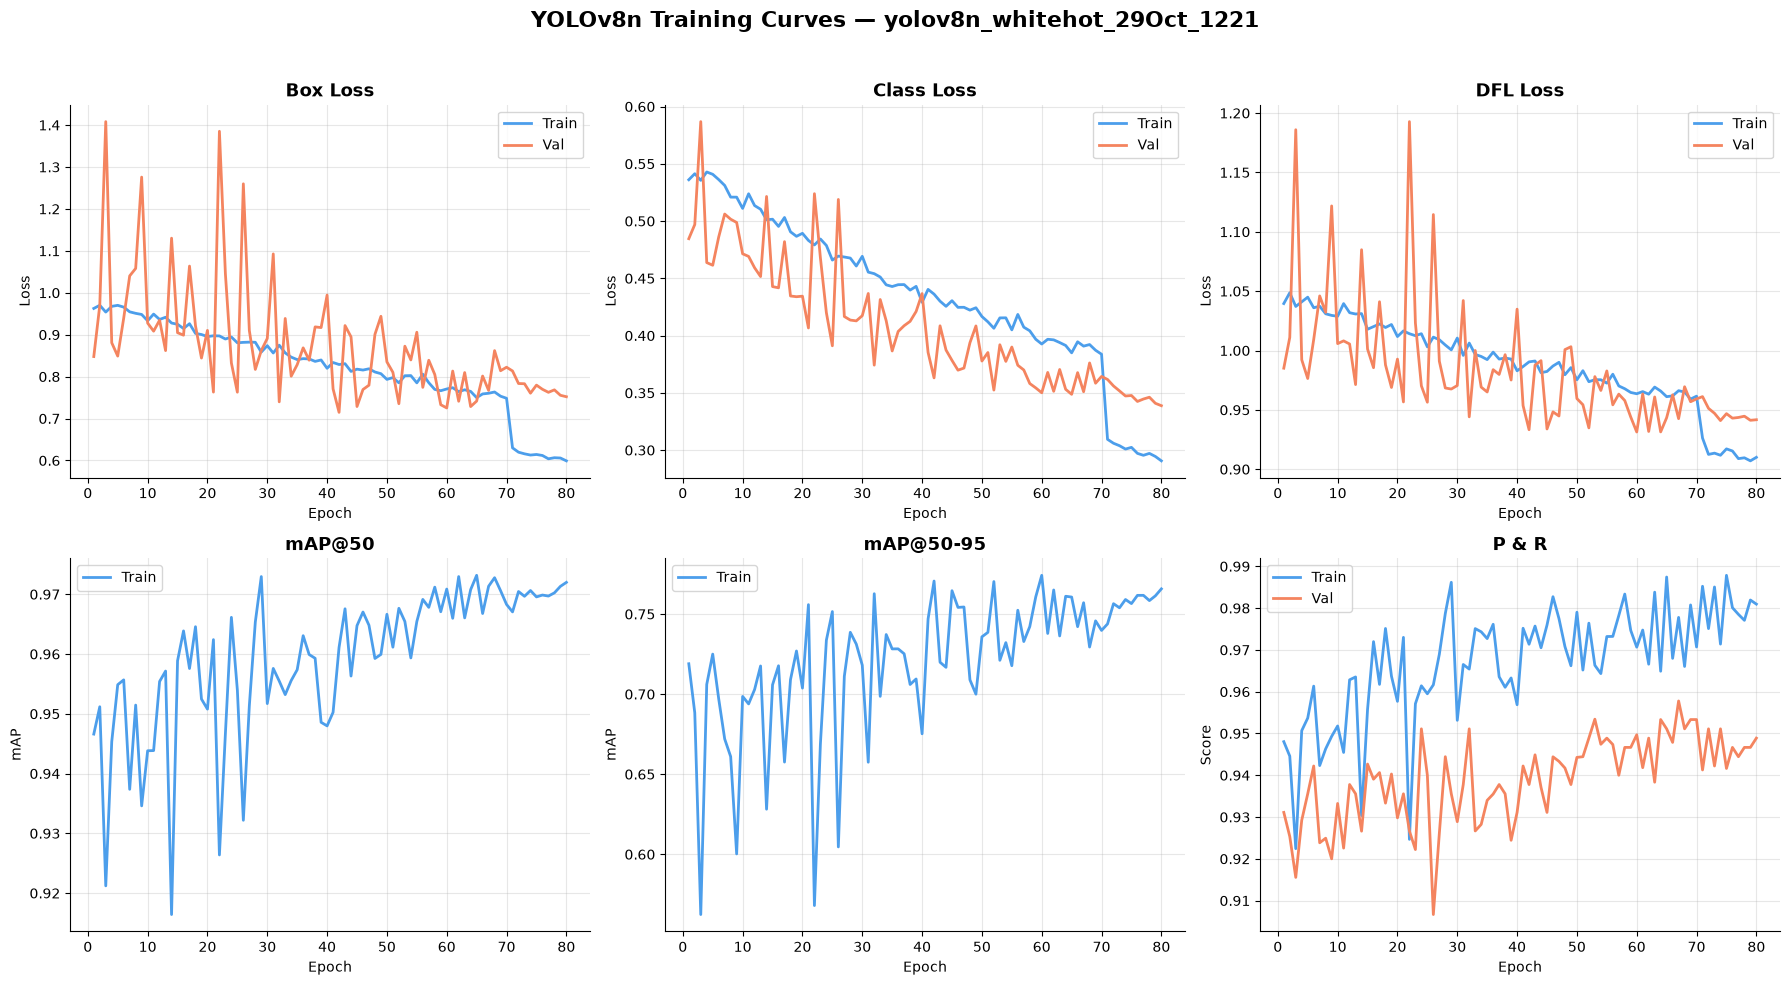

Saved: C:\Projects\mscSem3\runs\detect\yolov8n_whitehot_29Oct_1221\training_curves_custom.png


In [19]:
import pandas as pd

csv_path = SAVE_DIR / 'results.csv'

if csv_path.exists():
    df = pd.read_csv(csv_path)
    df.columns = [c.strip() for c in df.columns]

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    fig.suptitle(f'YOLOv8n Training Curves — {RUN_NAME}', fontsize=16, fontweight='bold')
    COLOR_T, COLOR_V = '#4C9EEB', '#F4845F'

    def plot_metric(ax, col_t, col_v=None, title='', ylabel=''):
        epochs = df.index + 1
        if col_t in df.columns:
            ax.plot(epochs, df[col_t], color=COLOR_T, label='Train', linewidth=2)
        if col_v and col_v in df.columns:
            ax.plot(epochs, df[col_v], color=COLOR_V, label='Val', linewidth=2)
        ax.set_title(title, fontsize=13, fontweight='bold')
        ax.set_xlabel('Epoch'); ax.set_ylabel(ylabel)
        ax.legend(); ax.grid(True, alpha=0.3)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    plot_metric(axes[0,0], 'train/box_loss',       'val/box_loss',       'Box Loss',   'Loss')
    plot_metric(axes[0,1], 'train/cls_loss',       'val/cls_loss',       'Class Loss', 'Loss')
    plot_metric(axes[0,2], 'train/dfl_loss',       'val/dfl_loss',       'DFL Loss',   'Loss')
    plot_metric(axes[1,0], 'metrics/mAP50(B)',     None,                 'mAP@50',     'mAP')
    plot_metric(axes[1,1], 'metrics/mAP50-95(B)',  None,                 'mAP@50-95',  'mAP')
    plot_metric(axes[1,2], 'metrics/precision(B)', 'metrics/recall(B)',  'P & R',      'Score')

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    out = SAVE_DIR / 'training_curves_custom.png'
    plt.savefig(out, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved: {out}')
else:
    print(f'results.csv not found at {csv_path}')

## Cell 10 — Per-Class AP@50 Bar Chart

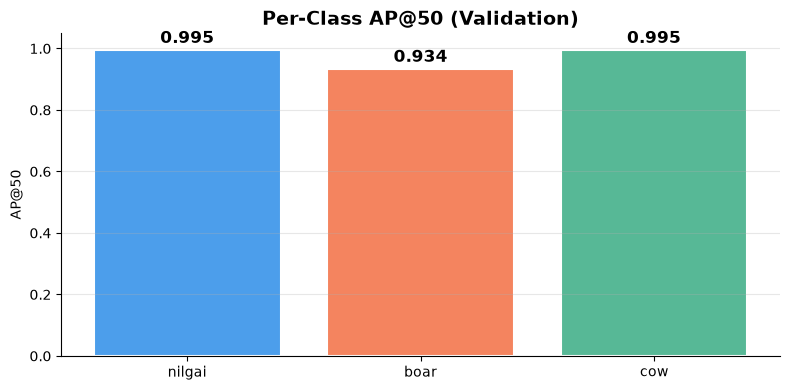

In [20]:
if hasattr(val_results.box, 'ap_class_index'):
    ap50_per_class = val_results.box.ap50
    class_idx      = val_results.box.ap_class_index
    names          = [CLASS_NAMES[i] for i in class_idx]

    fig, ax = plt.subplots(figsize=(8, 4))
    colors  = ['#4C9EEB', '#F4845F', '#57B896', '#A78BFA']
    bars    = ax.bar(names, ap50_per_class, color=colors[:len(names)], edgecolor='white', linewidth=1.5)

    for bar, v in zip(bars, ap50_per_class):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{v:.3f}', ha='center', va='bottom', fontweight='bold', fontsize=12)

    ax.set_title('Per-Class AP@50 (Validation)', fontsize=14, fontweight='bold')
    ax.set_ylabel('AP@50'); ax.set_ylim(0, 1.05)
    ax.grid(True, axis='y', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    plt.savefig(SAVE_DIR / 'per_class_ap50.png', dpi=150)
    plt.show()
else:
    print('Per-class AP not available.')

## Cell 11 — Sample Test Predictions

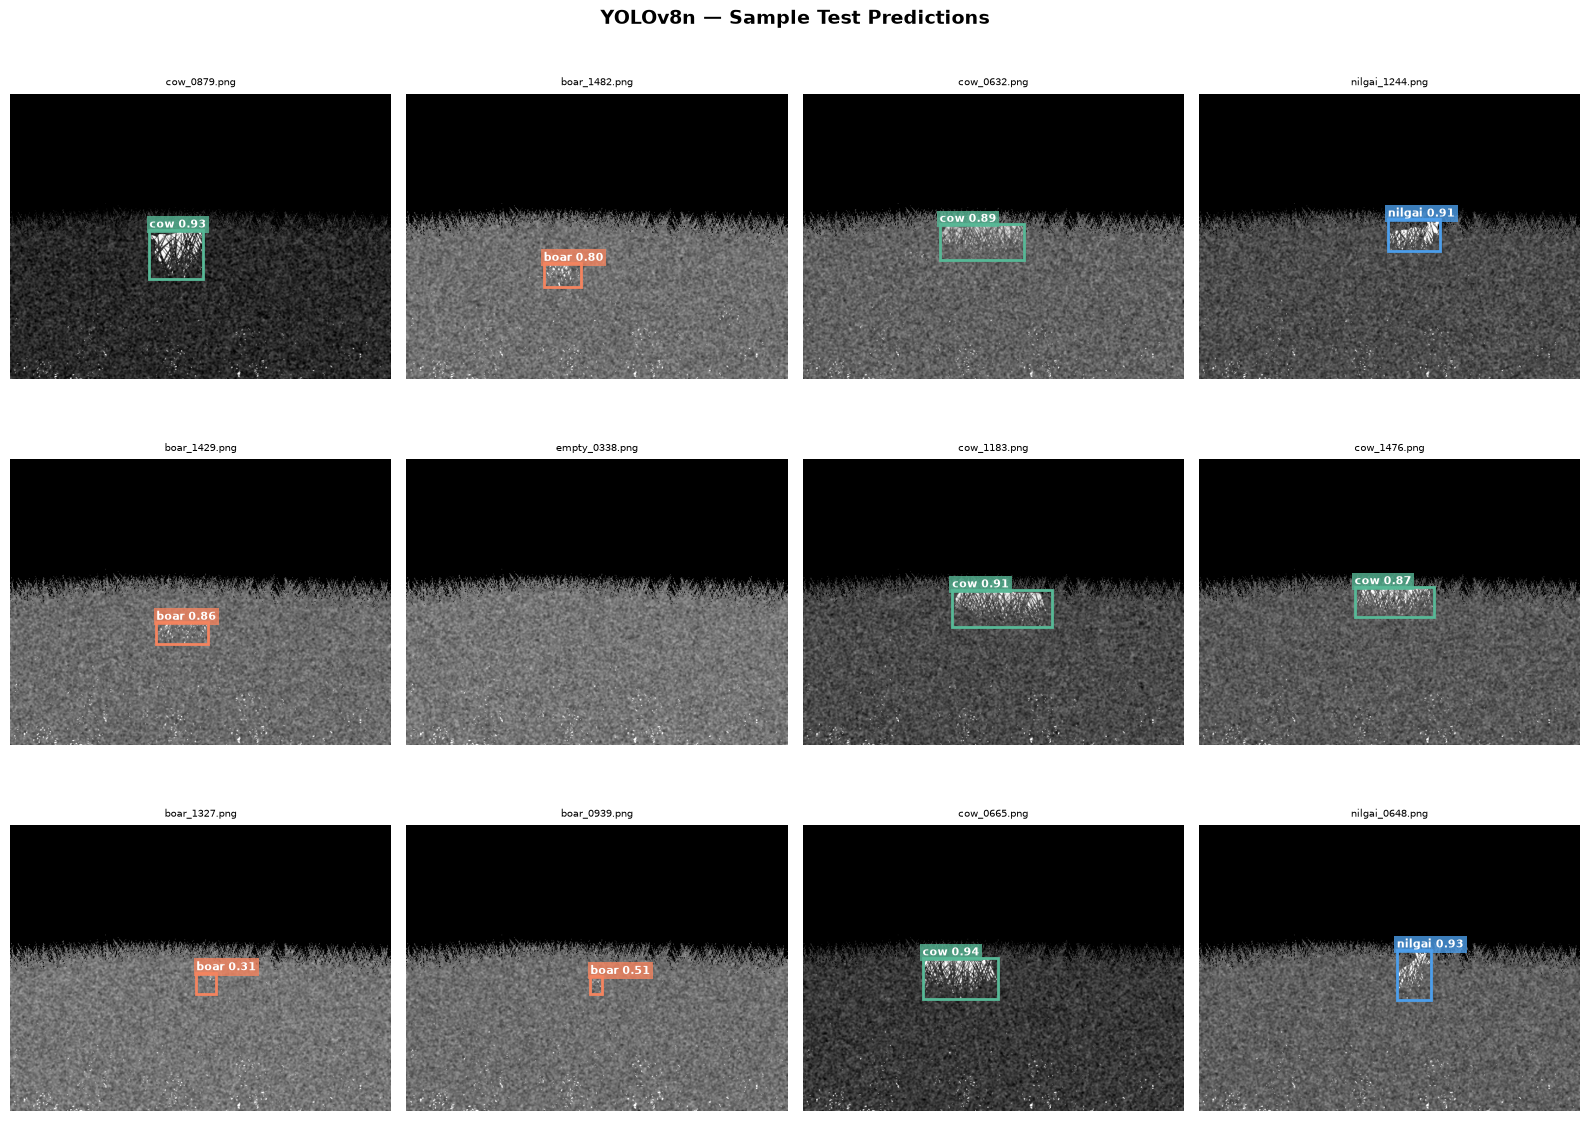

Saved: C:\Projects\mscSem3\runs\detect\yolov8n_whitehot_29Oct_1221\sample_predictions.png


In [21]:
from PIL import Image
import textwrap

TEST_IMG_DIR = DATASET_DIR / 'images' / 'test'
test_images  = sorted(TEST_IMG_DIR.glob('*.jpg')) + sorted(TEST_IMG_DIR.glob('*.png'))
SAMPLE_N     = min(12, len(test_images))
samples      = random.sample(test_images, SAMPLE_N)

preds = best_model.predict(
    source  = [str(p) for p in samples],
    imgsz   = IMG_SIZE,
    conf    = 0.25,
    iou     = 0.45,
    device  = DEVICE,
    verbose = False,
)

COLORS = {'nilgai': '#4C9EEB', 'boar': '#F4845F', 'cow': '#57B896'}
cols = 4
rows = (SAMPLE_N + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 4))
axes = axes.flatten()

for i, (res, ax) in enumerate(zip(preds, axes)):
    img = np.array(Image.open(res.path).convert('RGB'))
    ax.imshow(img)
    ax.axis('off')
    if res.boxes is not None and len(res.boxes):
        for box in res.boxes:
            x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
            cls_id   = int(box.cls[0])
            conf_val = float(box.conf[0])
            label    = CLASS_NAMES[cls_id] if cls_id < len(CLASS_NAMES) else str(cls_id)
            color    = COLORS.get(label, '#ffffff')
            rect = mpatches.Rectangle((x1, y1), x2-x1, y2-y1,
                                      linewidth=2, edgecolor=color, facecolor='none')
            ax.add_patch(rect)
            ax.text(x1, y1 - 4, f'{label} {conf_val:.2f}', color='white',
                    fontsize=8, fontweight='bold',
                    bbox=dict(facecolor=color, alpha=0.8, pad=2, edgecolor='none'))
    ax.set_title('\n'.join(textwrap.wrap(Path(res.path).name, 20)), fontsize=7)

for ax in axes[SAMPLE_N:]:
    ax.set_visible(False)

plt.suptitle('YOLOv8n — Sample Test Predictions', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(SAVE_DIR / 'sample_predictions.png', dpi=150)
plt.show()
print(f'Saved: {SAVE_DIR / "sample_predictions.png"}')

## Cell 12 — Export to ONNX (optional)

In [2]:
from ultralytics import YOLO

# 1. Redefine the image size you used during training
IMG_SIZE = 640

# 2. Load your saved best weights 
best_model = YOLO(r"C:\Projects\mscSem3\runs\detect\yolov8n_whitehot_29Oct_1221\weights\best.pt")

# 3. Export the model to ONNX
onnx_path = best_model.export(format='onnx', imgsz=IMG_SIZE, opset=17, simplify=True)
print(f'ONNX saved: {onnx_path}')


# # Uncomment to export
# onnx_path = best_model.export(format='onnx', imgsz=IMG_SIZE, opset=17, simplify=True)
# print(f'ONNX saved: {onnx_path}')
# print('ONNX export — uncomment above to run.')

Ultralytics 8.4.182  Python-3.12.10 torch-2.14.1+cu132 CPU (AMD Ryzen 7 250 w/ Radeon 780M Graphics)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs

PyTorch: starting from 'C:\Projects\mscSem3\runs\detect\yolov8n_whitehot_29Oct_1221\weights\best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 7, 8400) (6.2 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
   ---------------------------------------- 0.0/7.9 MB ? eta -:--:--
   - -------------------------------------- 0.3/7.9 MB ? eta -:--:--
   ------ --------------------------------- 1.3/7.9 MB 4.5 MB/s eta 0:00:02
   ----------- ---------------------------- 2.4/7.9 MB 4.8 MB/s eta 0:00:02
   ----------------- ---------------------- 3.4/7.9 MB 4.8 MB/s eta 0:00:01
   --------------------- ------------------ 4.2/7.9 MB 4.7 MB/s eta 0:00:01
   ----------------------- ---------------- 4.7/7.9 MB 4.2 M

## Cell 13 — Final Summary

In [23]:
print('=' * 60)
print('  TRAINING SUMMARY')
print('=' * 60)
print(f'  Model         : YOLOv8n')
print(f'  Dataset       : white_hot  ({NUM_CLASSES} classes)')
print(f'  Classes       : {CLASS_NAMES}')
print(f'  Device        : {DEVICE}')
print(f'  Batch size    : {BATCH_SIZE}')
print(f'  Image size    : {IMG_SIZE}')
print(f'  AMP (fp16)    : {USE_AMP}')
print(f'  Run dir       : {SAVE_DIR}')
print(f'  Best weights  : {BEST_PT}')
print('-' * 60)
print(f'  Val  mAP@50   : {val_results.box.map50:.4f}')
print(f'  Val  mAP@50-95: {val_results.box.map:.4f}')
print(f'  Test mAP@50   : {test_results.box.map50:.4f}')
print(f'  Test mAP@50-95: {test_results.box.map:.4f}')
print('=' * 60)

  TRAINING SUMMARY
  Model         : YOLOv8n
  Dataset       : white_hot  (3 classes)
  Classes       : ['nilgai', 'boar', 'cow']
  Device        : cuda:0
  Batch size    : 32
  Image size    : 640
  AMP (fp16)    : True
  Run dir       : C:\Projects\mscSem3\runs\detect\yolov8n_whitehot_29Oct_1221
  Best weights  : C:\Projects\mscSem3\runs\detect\yolov8n_whitehot_29Oct_1221\weights\best.pt
------------------------------------------------------------
  Val  mAP@50   : 0.9745
  Val  mAP@50-95: 0.7740
  Test mAP@50   : 0.9761
  Test mAP@50-95: 0.7943
